# La ecuación clásica del tamaño medio en un tiro, y el término que la gobierna

**Pregunta:** ¿Qué predice la ecuación clásica para un tiro, y qué término la gobierna?

**Nivel 1: Fundamentos** · Requiere: 01-the-data/02-geometry-reconstruction · Tiempo de lectura: unos 25 minutos

## Objetivos

El predictor más antiguo de la escalera es una ecuación cerrada: el tamaño medio de Kuznetsov de 1973 con la corrección de resistencia del explosivo que agregó Cunningham. No necesita datos de entrenamiento, solo una geometría en metros y un número para la roca. Este notebook la ejecuta sobre un solo tiro, la descompone en sus factores, pregunta cuál de ellos gobierna la respuesta, y luego la ejecuta sobre una campaña entera para ver hasta dónde se puede confiar en un solo tiro.

Al terminar, usted habrá:

- construido el tamaño medio predicho del tiro `En1` factor por factor y coincidido con `kuznetsov_x50_m` del motor;
- visto qué factor lleva la mayor parte del tamaño, y cómo responde la predicción cuando cada entrada se mueve un 20 por ciento;
- predicho los 12 tiros de la campaña de Enusa y puntuado la ecuación contra las mediciones y contra una constante;
- entendido por qué el único número libre de la ecuación, el factor de roca `A`, es el tema del notebook siguiente.

## Preparación

Instale los paquetes con las versiones exactas de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación siguiente importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número, fija el estilo de los gráficos y define `show_table`, un ayudante de cuatro líneas que dibuja filas como tabla Markdown porque el entorno de notebooks no tiene `pandas`.

In [1]:
# Importaciones, versiones fijadas, estilo de gráficos y un ayudante de tablas
import dataclasses
from importlib.metadata import version

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Dibujar las filas como tabla Markdown, las primeras `left` columnas a la izquierda y las demás a la derecha
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

Dos fuentes, ambas leídas desde el motor, sin necesitar ningún archivo de `data/`:

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 12 tiros de Enusa con `x50` medido, y el resto del corpus | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| La ecuación como se imprime, y los factores de roca por sitio | Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 2 y 3) | la ecuación se reproduce con cita | `kuznetsov_x50_m` y `SITE_ROCK_FACTOR` del motor |

## Método

El tamaño medio de fragmento en centímetros es

```
x50 = A * (V / Q)^0.8 * Q^(1/6) * (RWS / 115)^(-19/30)
```

con `V` el volumen de roca que rompe cada perforación (m3), `Q` la masa de explosivo en ella (kg), `RWS` la resistencia relativa en peso del explosivo en la escala donde el ANFO vale 100, y `A` el factor de roca. El factor 115 es la resistencia del TNT en esa escala, y el exponente -19/30 es la corrección de Cunningham tal como la imprimen Hudaverdi, Kulatilake y Kuzu 2010 (https://doi.org/10.1002/nag.957, Ec. 1) y Amoako, Jha y Zhong 2022 (https://doi.org/10.3390/mining2020013, Ecs. 2 y 3).

Lea los términos. Como `Q = Pf * V`, con `Pf` el factor de carga, `V / Q` es el recíproco del factor de carga: una carga más rica da una fragmentación más fina. `Q^(1/6)` deja que una perforación mayor fragmente algo más grueso al mismo factor de carga. El término de resistencia hace más fino a un explosivo más fuerte. `A` es la roca: un solo número para toda la campaña.

### Paso 1: el tiro, su patrón y su factor de roca

La celda carga el corpus, elige el tiro `En1` de Enusa y reconstruye su patrón absoluto en metros con `reconstruct_pattern` (el notebook 02 del tema anterior). El factor de roca de Enusa viene de la tabla de factores por sitio del motor, `SITE_ROCK_FACTOR`; de dónde sale ese número es el tema del notebook siguiente, así que aquí es un dato. La tabla lista los cuatro números que consume la ecuación, más el tamaño medido con el que se comparará.

In [2]:
# Cargar el corpus, tomar el tiro En1 de Enusa y reconstruir su patrón en metros
train = bf.load_training_corpus()
blast = next(b for b in train if b.blast_id == "En1")
pattern = bf.reconstruct_pattern(blast)
rock_factor = bf.SITE_ROCK_FACTOR[blast.site]
rows = [
    ("volumen de roca V (m3)", f"{pattern.rock_volume_m3:.3f}"),
    ("masa de explosivo Q (kg)", f"{pattern.charge_mass_kg:.3f}"),
    ("resistencia relativa en peso RWS (ANFO = 100)", f"{pattern.explosive.rws:g}"),
    ("factor de roca A de Enusa", f"{rock_factor}"),
    ("x50 medido (m)", f"{blast.x50_m}"),
]
show_table(["magnitud", "valor para En1"], rows)

| magnitud | valor para En1 |
|:---|---:|
| volumen de roca V (m3) | 150.238 |
| masa de explosivo Q (kg) | 72.114 |
| resistencia relativa en peso RWS (ANFO = 100) | 100 |
| factor de roca A de Enusa | 10.97 |
| x50 medido (m) | 0.37 |

El tiro rompe 150,238 m3 de roca con 72,114 kg de ANFO, cuya resistencia define el 100 de la escala, así que el término de resistencia resultará cercano a uno. El factor de roca es 10,97, y el tamaño medio medido es 0,37 m. Una precaución: el factor de 10,97 no es una propiedad medida de la roca de Enusa sino un número recuperado de predicciones publicadas para esta misma campaña, lo que hace parcialmente circular cualquier acuerdo con Enusa. La tabla dice qué entra a la ecuación; no dice que las entradas sean independientes de la respuesta.

### Paso 2: la ecuación, un factor por variable

Cada factor de la ecuación tiene su propia variable, así que cada intermedio es visible: el factor de roca, el término de volumen `(V/Q)^0.8`, el término de perforación `Q^(1/6)` y el término de resistencia. Su producto es el tamaño predicho en centímetros. Como los factores se multiplican, la forma natural de preguntar cuánto aporta cada uno es en escala logarítmica: la parte de `ln x50` que lleva cada factor suma 100 por ciento. La tabla muestra los multiplicadores y esas partes.

In [3]:
# Los cuatro factores de la ecuación, una variable cada uno, y su producto en centímetros y metros
V = pattern.rock_volume_m3
Q = pattern.charge_mass_kg
terms = {
    "A": rock_factor,
    "(V/Q)^0.8": (V / Q) ** 0.8,
    "Q^(1/6)": Q ** (1 / 6),
    "(RWS/115)^(-19/30)": (pattern.explosive.rws / 115.0) ** (-19.0 / 30.0),
}
x50_cm = np.prod(list(terms.values()))
rows = [(name, f"{value:.4f}", f"{np.log(value) / np.log(x50_cm):.1%}") for name, value in terms.items()]
show_table(["factor", "valor (un multiplicador)", "parte de ln x50"], rows)
print(f"x50 = {x50_cm:.2f} cm = {x50_cm / 100:.4f} m")

| factor | valor (un multiplicador) | parte de ln x50 |
|:---|---:|---:|
| A | 10.9700 | 63.3% |
| (V/Q)^0.8 | 1.7989 | 15.5% |
| Q^(1/6) | 2.0402 | 18.8% |
| (RWS/115)^(-19/30) | 1.0926 | 2.3% |

x50 = 43.99 cm = 0.4399 m


Los cuatro factores se multiplican en 43,99 cm, o 0,4399 m. El factor de roca vale 10,97 por sí solo y lleva el 63,3 por ciento de `ln x50`; el término de perforación, 2,0402, lleva el 18,8 por ciento; el término de volumen, 1,7989, lleva el 15,5 por ciento; y la corrección de resistencia, 1,0926, solo el 2,3 por ciento porque el explosivo es ANFO. Así que la mayor parte de la respuesta la fija el único número que el corpus no entrega, y el resto la geometría. La tabla no dice si el producto es correcto, solo cómo se compone; la celda siguiente lo compara con el motor.

### Verificación de reproducción: el producto a mano contra el motor

`bf.kuznetsov_x50_m` implementa la misma ecuación. La celda la llama sobre el mismo patrón y la compara con el producto construido a mano, e imprime la diferencia con la medición. Esta es la única verificación de reproducción del notebook: los demás números del motor y los artefactos versionados de la ejecución offline los cubren las pruebas del producto.

In [4]:
# La ecuación del propio motor sobre el mismo patrón, contra el producto a mano
engine = bf.kuznetsov_x50_m(pattern, rock_factor)
print("a mano igual al motor a 1e-12 m:", np.isclose(x50_cm / 100, engine, rtol=0, atol=1e-12))
print(f"motor: {engine:.4f} m | medido: {blast.x50_m} m | diferencia: {engine - blast.x50_m:+.3f} m")

a mano igual al motor a 1e-12 m: True
motor: 0.4399 m | medido: 0.37 m | diferencia: +0.070 m


El producto a mano y el motor coinciden a 1e-12 m, así que la ecuación de este notebook es la del motor y nada se esconde dentro. El motor predice 0,4399 m para un tiro que midió 0,37 m, un exceso de 0,070 m. Un solo tiro no puede decir si ese error es típico, por lo que el último paso ejecuta la campaña completa.

### Paso 3: qué factor gobierna el tamaño

La celda construye el tamaño predicho desde 1 cm, multiplicando un factor por vez: la barra de cada factor va desde el tamaño acumulado antes de él hasta el tamaño acumulado después, en un eje logarítmico donde razones iguales tienen igual longitud. La línea punteada marca el tamaño medido de `En1`. Fíjese en qué barra es la más larga y dónde el tamaño acumulado cruza la medición.

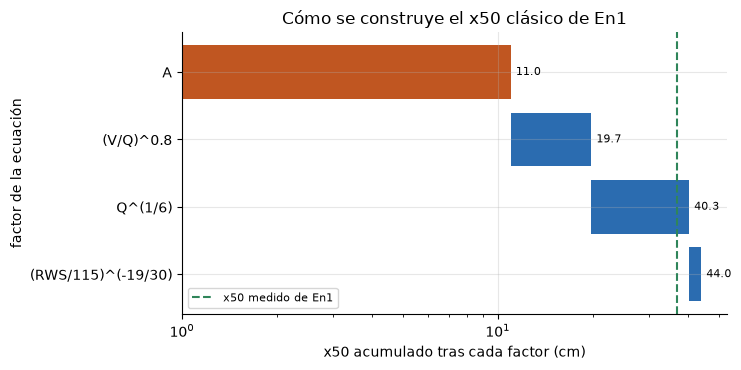

In [5]:
# Construir x50 factor a factor: el producto acumulado tras cada término, en eje logarítmico
names = list(terms)
running = np.cumprod(list(terms.values()))
starts = np.concatenate([[1.0], running[:-1]])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(range(len(names)), running - starts, left=starts, color=["#c05621", "#2b6cb0", "#2b6cb0", "#2b6cb0"])
for position, total in enumerate(running):
    ax.text(total * 1.04, position, f"{total:.1f}", va="center", fontsize=8)
ax.axvline(blast.x50_m * 100, color="#2f855a", ls="--", label="x50 medido de En1")
ax.set_xscale("log")
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_ylabel("factor de la ecuación")
ax.set_xlabel("x50 acumulado tras cada factor (cm)")
ax.set_title("Cómo se construye el x50 clásico de En1")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

El factor de roca por sí solo lleva el tamaño de 1 cm a 11,0 cm, la barra más larga con diferencia. El término de volumen lo lleva a 19,7 cm, el de perforación a 40,3 cm y la corrección de resistencia a 44,0 cm, un poco por encima de los 37 cm medidos. Así que la predicción cruza la medición durante el término de perforación, y son los dos últimos factores los que la empujan por encima. La figura muestra la composición de un tiro y no dice nada de otro: las mismas barras para un tiro de otra campaña partirían de un factor de roca distinto, y el factor de roca es el término que nadie midió.

### Paso 4: cómo responde el tamaño a cada entrada

La composición dice cómo se construye un tamaño; la sensibilidad dice qué hace un cambio. La celda mueve una entrada por vez en menos 20 y más 20 por ciento y registra el cambio relativo del tamaño predicho: el factor de roca, el factor de carga, las tres longitudes del patrón (bordo, espaciamiento, altura de banco) y la resistencia del explosivo. Se llama a `kuznetsov_x50_m` del motor sobre cada patrón modificado; nada se deriva a mano. Busque qué entradas mueven la respuesta tanto como se mueven ellas mismas, y cuáles apenas la mueven.

In [6]:
# Mover una entrada por vez en -20 y +20 por ciento y registrar cómo responde el x50 predicho
base = bf.kuznetsov_x50_m(pattern, rock_factor)
fields = {"factor de carga Pf": "powder_factor_kg_m3", "bordo B": "burden_m",
          "espaciamiento S": "spacing_m", "altura de banco H": "bench_height_m"}
response = {}
for k in (0.8, 1.2):
    response.setdefault("factor de roca A", []).append(bf.kuznetsov_x50_m(pattern, rock_factor * k) / base - 1)
    for label, field in fields.items():
        moved = dataclasses.replace(pattern, **{field: getattr(pattern, field) * k})
        response.setdefault(label, []).append(bf.kuznetsov_x50_m(moved, rock_factor) / base - 1)
    stronger = dataclasses.replace(pattern.explosive, rws=pattern.explosive.rws * k)
    moved = dataclasses.replace(pattern, explosive=stronger)
    response.setdefault("resistencia del explosivo RWS", []).append(bf.kuznetsov_x50_m(moved, rock_factor) / base - 1)
rows = [(label, f"{low:+.1%}", f"{high:+.1%}") for label, (low, high) in response.items()]
show_table(["entrada movida", "con -20 %", "con +20 %"], rows)

| entrada movida | con -20 % | con +20 % |
|:---|---:|---:|
| factor de roca A | -20.0% | +20.0% |
| factor de carga Pf | +15.2% | -10.9% |
| bordo B | -3.7% | +3.1% |
| espaciamiento S | -3.7% | +3.1% |
| altura de banco H | -3.7% | +3.1% |
| resistencia del explosivo RWS | +15.2% | -10.9% |

El factor de roca mueve el tamaño uno a uno, menos 20,0 y más 20,0 por ciento. El factor de carga y la resistencia del explosivo tienen efectos idénticos, más 15,2 por ciento al bajarlos y menos 10,9 por ciento al subirlos, porque ambos entran con el mismo exponente, -19/30: con `Q = Pf * V`, la ecuación se reduce a una potencia del factor de carga. Las tres longitudes del patrón mueven el tamaño solo en menos 3,7 y más 3,1 por ciento, porque entran únicamente por `Q^(1/6)`. Así que la geometría del patrón apenas cambia la respuesta, mientras que la carga y la roca sí.

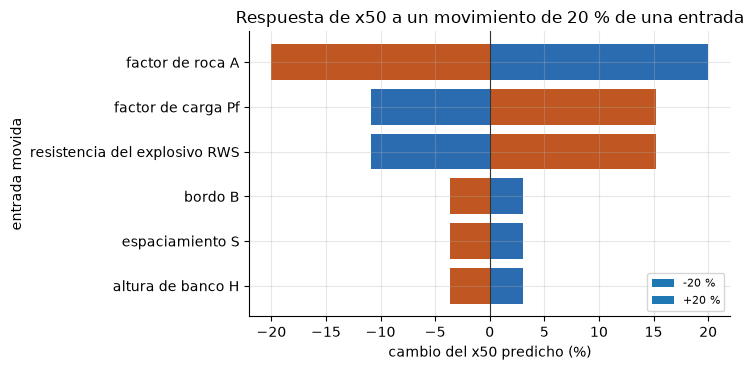

In [7]:
# La misma respuesta como gráfico de tornado, la entrada más influyente arriba
order = sorted(response, key=lambda label: -max(abs(v) for v in response[label]))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for position, label in enumerate(order):
    low, high = response[label]
    ax.barh(position, low * 100, color="#c05621")
    ax.barh(position, high * 100, color="#2b6cb0")
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_ylabel("entrada movida")
ax.set_xlabel("cambio del x50 predicho (%)")
ax.set_title("Respuesta de x50 a un movimiento de 20 % de una entrada")
ax.barh([], [], color="#c05621", label="-20 %")
ax.barh([], [], color="#2b6cb0", label="+20 %")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

El gráfico de tornado ordena las entradas según cuánto mueven el tamaño predicho, naranja para una disminución de la entrada y azul para un aumento. El factor de roca se extiende más lejos en ambas direcciones, el factor de carga y la resistencia del explosivo vienen después con la misma forma asimétrica, y bordo, espaciamiento y altura de banco son tres barras cortas idénticas. La imagen muestra la respuesta de un tiro en el entorno de su propio diseño; no muestra cómo interactúan las respuestas, y no dice qué entradas puede cambiar realmente un ingeniero: el factor de roca no se puede elegir, el factor de carga y el patrón sí.

### Paso 5: la campaña completa

Un tiro no prueba nada, así que la celda predice los 12 tiros de Enusa con el predictor `Kuznetsov` del motor y los puntúa con `bf.score`, que nombra cada estadístico. La referencia es el modelo nulo, que predice la media del corpus de entrenamiento para cada tiro y no usa ninguna entrada: un predictor que no puede superar a una constante no tiene habilidad que informar. La tabla imprime ambos, con los dos estadísticos que esta literatura llama r2 bajo sus propios nombres: la correlación al cuadrado, y la varianza explicada respecto de la línea de identidad.

In [8]:
# Predecir los 12 tiros de Enusa y puntuar la ecuación, con la media de entrenamiento como referencia
enusa = [b for b in train if b.site == "Enusa"]
predictions = bf.Kuznetsov().predict(enusa)
score = bf.score(enusa, predictions, method="kuznetsov")
null = bf.null_model_score(enusa, training_mean_m=bf.training_mean(train))
rows = []
for label, s in (("ecuación clásica", score), ("media de entrenamiento (nulo)", null)):
    r2 = f"{s.pearson_r2:.3f}" if np.isfinite(s.pearson_r2) else "-"
    errors = (f"{s.rmse_m:.3f}", f"{s.bias_m:+.3f}", f"{s.mae_m:.3f}", f"{s.mape_pct:.1f}")
    rows.append((label, *errors, r2, f"{s.r2_identity:.3f}"))
header = ["predictor", "RMSE (m)", "sesgo (m)", "MAE (m)", "MAPE (%)", "r2 de Pearson",
          "r2 respecto de la identidad"]
show_table(header, rows)
distinct = len({round(p.x50_m, 6) for p in predictions})
print("tiros puntuados:", score.n_scored, "| valores predichos distintos:", distinct)
values = [round(p.x50_m, 6) for p in predictions]
common = max(set(values), key=values.count)
sharing = [b.x50_m for b, v in zip(enusa, values) if v == common]
span = f"{min(sharing):.2f} a {max(sharing):.2f}"
print(f"{len(sharing)} tiros comparten un valor predicho; sus tamaños medidos (m): {span}")
over = sum(p.x50_m > b.x50_m for p, b in zip(predictions, enusa))
print("tiros predichos más gruesos que lo medido:", over, "de", len(enusa))

| predictor | RMSE (m) | sesgo (m) | MAE (m) | MAPE (%) | r2 de Pearson | r2 respecto de la identidad |
|:---|---:|---:|---:|---:|---:|---:|
| ecuación clásica | 0.147 | +0.105 | 0.122 | 34.9 | 0.017 | -1.643 |
| media de entrenamiento (nulo) | 0.130 | -0.093 | 0.100 | 22.7 | - | -1.066 |

tiros puntuados: 12 | valores predichos distintos: 5
5 tiros comparten un valor predicho; sus tamaños medidos (m): 0.33 a 0.46
tiros predichos más gruesos que lo medido: 10 de 12


La ecuación falla en 0,147 m de RMSE y predice más grueso que lo medido en promedio (sesgo +0,105 m), con 10 de los 12 tiros predichos más gruesos que lo medido. La correlación al cuadrado es 0,017, así que los tamaños predichos apenas siguen a los medidos, y la varianza explicada respecto de la identidad es -1,643, peor que una constante. El modelo nulo, que no usa ninguna entrada, está más cerca: RMSE 0,130 m y -1,066. La ecuación además devuelve solo 5 valores distintos para 12 tiros, porque tiros con el mismo patrón reciben la misma respuesta, mientras los tamaños medidos difieren. Esta es una sola campaña con poca dispersión, lo que perjudica a todo estadístico, pero significa que esta tabla no da evidencia de habilidad.

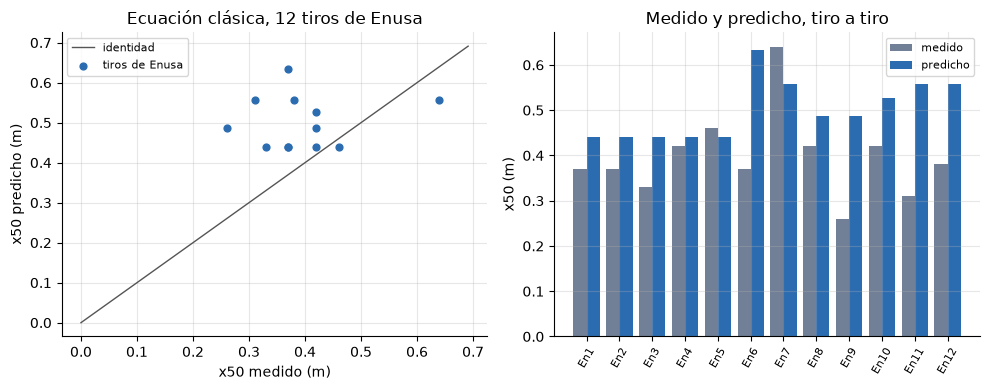

In [9]:
# Izquierda: x50 predicho contra medido en los 12 tiros. Derecha: ambos tamaños tiro a tiro
measured = np.array([b.x50_m for b in enusa])
predicted = np.array([p.x50_m for p in predictions])
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
limit = max(measured.max(), predicted.max()) * 1.08
left.plot([0, limit], [0, limit], color="#555", lw=1, label="identidad")
left.scatter(measured, predicted, s=24, color="#2b6cb0", label="tiros de Enusa")
left.set_xlabel("x50 medido (m)")
left.set_ylabel("x50 predicho (m)")
left.set_title("Ecuación clásica, 12 tiros de Enusa")
left.legend(fontsize=8)
positions = np.arange(len(enusa))
right.bar(positions - 0.2, measured, width=0.4, color="#718096", label="medido")
right.bar(positions + 0.2, predicted, width=0.4, color="#2b6cb0", label="predicho")
right.set_xticks(positions, [b.blast_id for b in enusa], rotation=60, fontsize=8)
right.set_ylabel("x50 (m)")
right.set_title("Medido y predicho, tiro a tiro")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

El panel izquierdo grafica el tamaño predicho contra el medido con la línea de identidad: casi todo punto queda por encima, y la nube no tiene pendiente que mencionar. El panel derecho pone ambos tamaños lado a lado tiro a tiro, y muestra la meseta: En1 a En5 comparten un valor predicho mientras sus tamaños medidos van de 0,33 a 0,46 m. La figura muestra que, dentro de Enusa, la ecuación no capta la variación que la campaña sí tiene. No muestra cómo le va entre campañas, donde el factor de roca cambia de un sitio a otro; esa comparación, y la pregunta de dónde sale el factor, son el notebook siguiente.

## Resultados

**Respuesta:** Para el tiro `En1` la ecuación clásica predice 0,4399 m contra 0,37 m medidos, y el término que la gobierna es el factor de roca: `A = 10.97` lleva el 63,3 por ciento de `ln x50`, frente al 15,5 y 18,8 por ciento de los términos de volumen y de perforación y el 2,3 por ciento de la corrección de resistencia. La respuesta lo confirma: mover `A` en 20 por ciento mueve el tamaño en 20 por ciento, el factor de carga y la resistencia del explosivo lo mueven en 15,2 y 10,9 por ciento en las dos direcciones, y cualquier longitud del patrón en solo 3,7 o 3,1 por ciento. Sobre los 12 tiros de Enusa la ecuación tiene un RMSE de 0,147 m, un sesgo de +0,105 m y una varianza explicada respecto de la identidad de -1,643, frente a 0,130 m y -1,066 de una constante.

**Qué se sigue.** Una decisión que dependa de esta ecuación depende de un número que nadie midió. El patrón, la entrada que un ingeniero puede cambiar con libertad, tiene poca palanca sobre su respuesta, mientras que el factor de carga tiene mucha. Y un solo tiro dice poco: la tabla de la campaña es el resumen honesto.

**Lo que este notebook no muestra.** El factor de Enusa se recuperó de predicciones publicadas para esta misma campaña, así que incluso el mal acuerdo está favorecido por conocimiento prestado. Una campaña tiene poca dispersión, así que todo estadístico de esta tabla es severo. Y nada aquí compara la ecuación con una campaña que nunca ha visto: esa es la pregunta del tema 04, y el notebook siguiente abre el factor de roca.

## Resumen

- La ecuación son cuatro multiplicadores: el factor de roca, un término de volumen, un término de tamaño de perforación y una corrección de resistencia.
- El factor de roca lleva el 63,3 por ciento de `ln x50` para `En1`, y las longitudes del patrón importan poco (mover una longitud 20 por ciento mueve el tamaño 3,7 o 3,1 por ciento).
- El motor y un producto a mano coinciden a 1e-12 m, y el motor predice 0,4399 m para un tiro que midió 0,37 m.
- Sobre los 12 tiros de Enusa la ecuación no está más cerca que una constante: RMSE 0,147 m contra 0,130 m.
- Siguiente: el notebook 02 abre el factor de roca, el único número que la ecuación no puede calcular desde la tabla.

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (Ec. 1, el corpus)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 2 y 3, la ecuación y sus unidades)
- Kuznetsov 1973 y Cunningham 1983, 1987 y 2005 son los originales de la ecuación y sus correcciones; el SDD registra que no se dispuso de sus textos primarios, así que este notebook los cita solo a través de los dos artículos anteriores.
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/